# 03. Integración y anotación de tipos celulares

In [2]:
from pathlib import Path

import harmonypy as hm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "02_qc.h5ad")
adata


AnnData object with n_obs × n_vars = 20369 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X)

In [3]:
COLORES = {"Sano": "#7a7a7a", "NL": "#5b8db8", "LS": "#c0504d"}
ORDEN = ["Sano", "NL", "LS"]
CMAP_EXPR = LinearSegmentedColormap.from_list("expresion", ["#e6e6e6", "#c0504d", "#5c1f1d"])


def colores_categoria(adata, columna, paleta):
    """Guarda en adata.uns los colores de una columna categórica, en el orden de sus categorías."""
    cats = adata.obs[columna].cat.categories
    if isinstance(paleta, dict):
        adata.uns[f"{columna}_colors"] = [paleta[c] for c in cats]
    else:
        adata.uns[f"{columna}_colors"] = [mcolors.to_hex(c) for c in paleta[:len(cats)]]


def umap_condicion(ax, adata, size):
    """UMAP coloreado por condición, en orden aleatorio para que ninguna condición tape a otra."""
    xy = adata.obsm["X_umap"]
    cond = adata.obs["condicion"].astype(str).to_numpy()
    orden_aleatorio = np.random.default_rng(0).permutation(len(cond))
    ax.scatter(xy[orden_aleatorio, 0], xy[orden_aleatorio, 1], s=size, linewidths=0,
               c=[COLORES[c] for c in cond[orden_aleatorio]], rasterized=True)
    for c in ORDEN:
        ax.scatter([], [], s=40, color=COLORES[c], label=c)
    ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
    ax.set_title("Condición")
    ax.set_axis_off()

COLORES_TIPO = {
    "Endotelial": "#6f8fb3",
    "Endotelial linfático": "#a9bfd8",
    "Fibroblasto": "#c99a6b",
    "Pericito": "#a67c9e",
    "Músculo liso": "#7d5b78",
    "Célula mioepitelial": "#c4b0d4",
    "Queratinocito basal": "#6f9a6a",
    "Queratinocito en diferenciación": "#b3cfa8",
    "Glándula sudorípara": "#d4b85a",
    "Melanocito": "#4f4038",
    "Célula de Schwann": "#9a9a9a",
    "Linfocito T": "#c0504d",
    "Mieloide": "#e3a07f",
}

## Normalización

Cada conteo se divide entre el total de moléculas de su célula, se multiplica por 10,000 y se aplica log(x + 1). Si una célula se secuenció con el doble de profundidad, todos sus genes aparecen con el doble de conteos sin que cambie su biología. Sin normalizar, las células se agruparían por profundidad y no por tipo. Los conteos crudos se guardan en `layers["counts"]` para la expresión diferencial.

In [4]:
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

## Genes variables

Scanpy agrupa los genes por su nivel promedio de expresión, calcula la dispersión de cada uno (varianza entre media) y la compara con la de genes de su mismo nivel. Así un gen muy expresado no se elige solo por tener números grandes. Con `batch_key` se prefieren los genes variables en muchas muestras.

In [5]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="muestra")
adata.var["highly_variable"].sum()

np.int64(2000)

## PCA

Muchos genes cambian juntos, por ejemplo todas las queratinas suben en queratinocitos. La PCA reemplaza los 2,000 genes por 50 ejes, cada uno una combinación de genes que varían juntos, ordenados de mayor a menor variación explicada. La gráfica muestra cuánta varianza aporta cada eje y dónde se cortó (30).

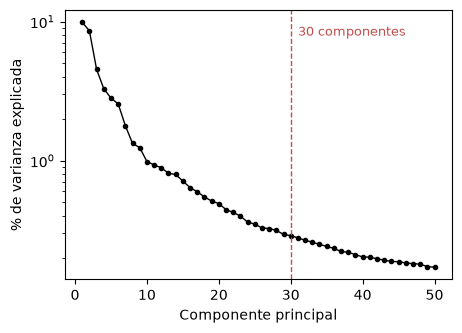

In [12]:
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")

var_pct = adata.uns["pca"]["variance_ratio"] * 100
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(range(1, len(var_pct) + 1), var_pct, "o-", color="black", ms=3, lw=1)
ax.axvline(30, color="#c0504d", ls="--", lw=1)
ax.text(31, var_pct.max() * 0.8, "30 componentes", color="#c0504d", fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("Componente principal")
ax.set_ylabel("% de varianza explicada")
fig.savefig(DIR_FIGURAS / "pca_varianza.png", dpi=300, bbox_inches="tight")

## Integración con Harmony

Las muestras tienen diferencias técnicas (por ejemplo, las de DER120 detectan más genes por célula). Sin corrección, las células se agruparían por muestra y no por tipo. Harmony agrupa las células en la PCA y, dentro de cada grupo, acerca las células de cada muestra al centro común, repitiendo hasta que deja de cambiar. Solo modifica esta representación, no los conteos.

In [6]:
ho = hm.run_harmony(adata.obsm["X_pca"], adata.obs, "muestra", random_state=0)
z = np.asarray(ho.Z_corr)
assert z.shape == adata.obsm["X_pca"].shape, z.shape
adata.obsm["X_pca_harmony"] = z

2026-11-02 12:34:50,294 - harmonypy - INFO - Running Harmony


2026-11-02 12:34:50,294 - harmonypy - INFO -   Parameters:


2026-11-02 12:34:50,295 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-02 12:34:50,295 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-02 12:34:50,295 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-02 12:34:50,296 - harmonypy - INFO -     epsilon_harmony: 0.01


... (13 outputs left out)

2026-11-02 12:34:50,468 - harmonypy - INFO - Iteration 3 of 10


2026-11-02 12:34:50,507 - harmonypy - INFO - Iteration 4 of 10


2026-11-02 12:34:50,547 - harmonypy - INFO - Iteration 5 of 10


2026-11-02 12:34:50,586 - harmonypy - INFO - Converged after 5 iterations


## Red de vecinos, Leiden y UMAP

Con los 30 componentes corregidos, cada célula se conecta con sus 15 células más parecidas, y así se forma una red.

Leiden divide esa red en comunidades con muchas más conexiones dentro que entre ellas. Su antecesor, Louvain, mueve cada célula a la comunidad de sus vecinas que más mejora esa medida (modularidad) y repite uniendo comunidades, pero puede formar comunidades internamente desconectadas. Leiden agrega un paso de refinamiento que divide las comunidades mal conectadas. La resolución (0.5) controla cuántos grupos se forman.

UMAP acomoda las células en dos dimensiones tratando de conservar a sus vecinas de la red. Se usa solo para dibujar: las distancias entre grupos lejanos y el tamaño de los grupos en el dibujo no tienen significado, y el agrupamiento se hace sobre la red de 30 dimensiones.

In [7]:
sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_pcs=30)
sc.tl.umap(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2,
             key_added="leiden", random_state=0)
adata.obs["leiden"].value_counts().sort_index()

leiden
0     1544
1     3314
2      490
3      286
4     1581
5     3103
6      559
7     2504
8     1382
9       22
10      11
11    1504
12      35
13       7
14      10
15     662
16     916
17     296
18     299
19     513
20     566
21     330
22     435
Name: count, dtype: int64

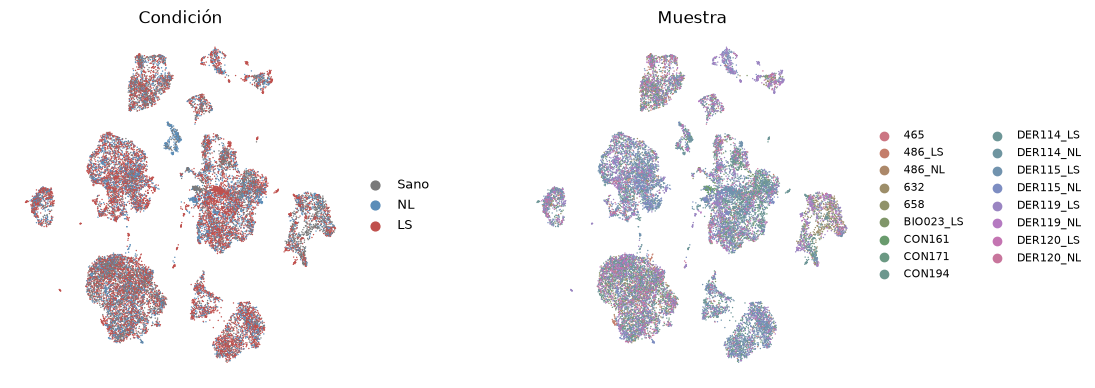

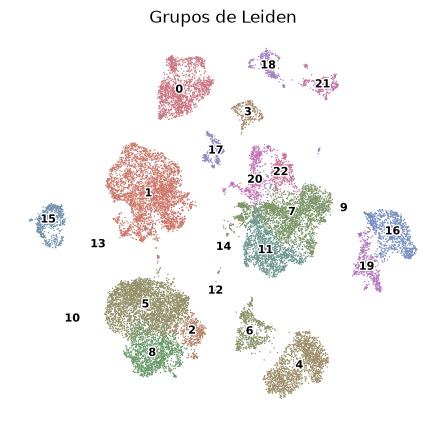

In [8]:
colores_categoria(adata, "condicion", COLORES)
colores_categoria(adata, "muestra", sns.husl_palette(adata.obs["muestra"].nunique(), s=0.45, l=0.6))
colores_categoria(adata, "leiden", sns.husl_palette(adata.obs["leiden"].nunique(), s=0.45, l=0.6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
umap_condicion(axes[0], adata, size=1)
sc.pl.umap(adata, color="muestra", ax=axes[1], frameon=False, size=4,
           title="Muestra", legend_fontsize=8, show=False)
fig.subplots_adjust(wspace=0.5)
fig.savefig(DIR_FIGURAS / "umap_muestra_condicion.png", dpi=300, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(5.5, 5))
sc.pl.umap(adata, color="leiden", ax=ax, frameon=False, size=4, title="Grupos de Leiden",
           legend_loc="on data", legend_fontsize=8, legend_fontoutline=2, show=False)
fig.savefig(DIR_FIGURAS / "umap_clusters.png", dpi=300, bbox_inches="tight")

## Anotación

En el dotplot cada fila es un grupo y cada columna un gen. El tamaño del punto es el porcentaje de células del grupo que expresan el gen, y el color su nivel promedio, escalado por gen de 0 a 1. Por eso el color compara grupos para un mismo gen, no un gen contra otro.

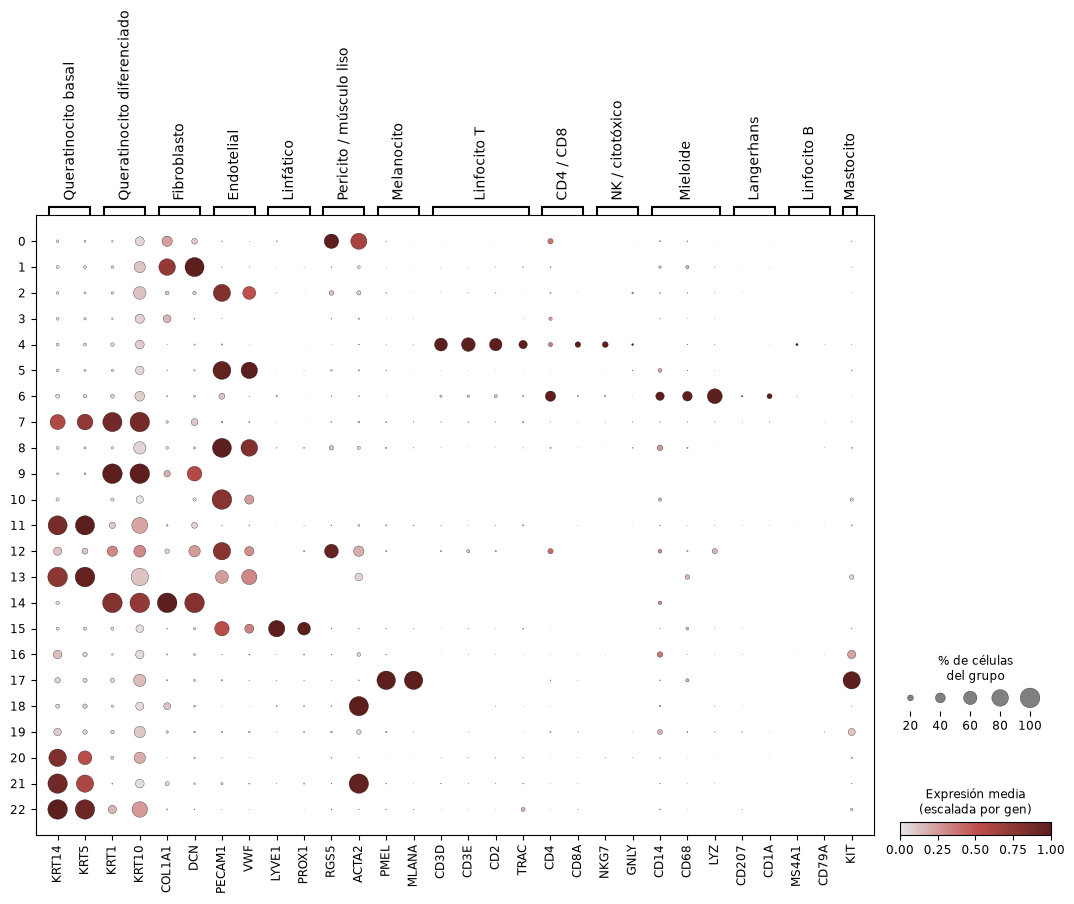

In [9]:
marcadores = {
    "Queratinocito basal": ["KRT14", "KRT5"],
    "Queratinocito diferenciado": ["KRT1", "KRT10"],
    "Fibroblasto": ["COL1A1", "DCN"],
    "Endotelial": ["PECAM1", "VWF"],
    "Linfático": ["LYVE1", "PROX1"],
    "Pericito / músculo liso": ["RGS5", "ACTA2"],
    "Melanocito": ["PMEL", "MLANA"],
    "Linfocito T": ["CD3D", "CD3E", "CD2", "TRAC"],
    "CD4 / CD8": ["CD4", "CD8A"],
    "NK / citotóxico": ["NKG7", "GNLY"],
    "Mieloide": ["CD14", "CD68", "LYZ"],
    "Langerhans": ["CD207", "CD1A"],
    "Linfocito B": ["MS4A1", "CD79A"],
    "Mastocito": ["TPSAB1", "KIT"],
}
marcadores = {k: [g for g in v if g in adata.var_names] for k, v in marcadores.items()}

sc.pl.dotplot(adata, marcadores, groupby="leiden", standard_scale="var", cmap=CMAP_EXPR, size_title="% de células\ndel grupo", colorbar_title="Expresión media\n(escalada por gen)",  show=False)
plt.savefig(DIR_FIGURAS / "dotplot_marcadores_clusters.png", dpi=300, bbox_inches="tight")

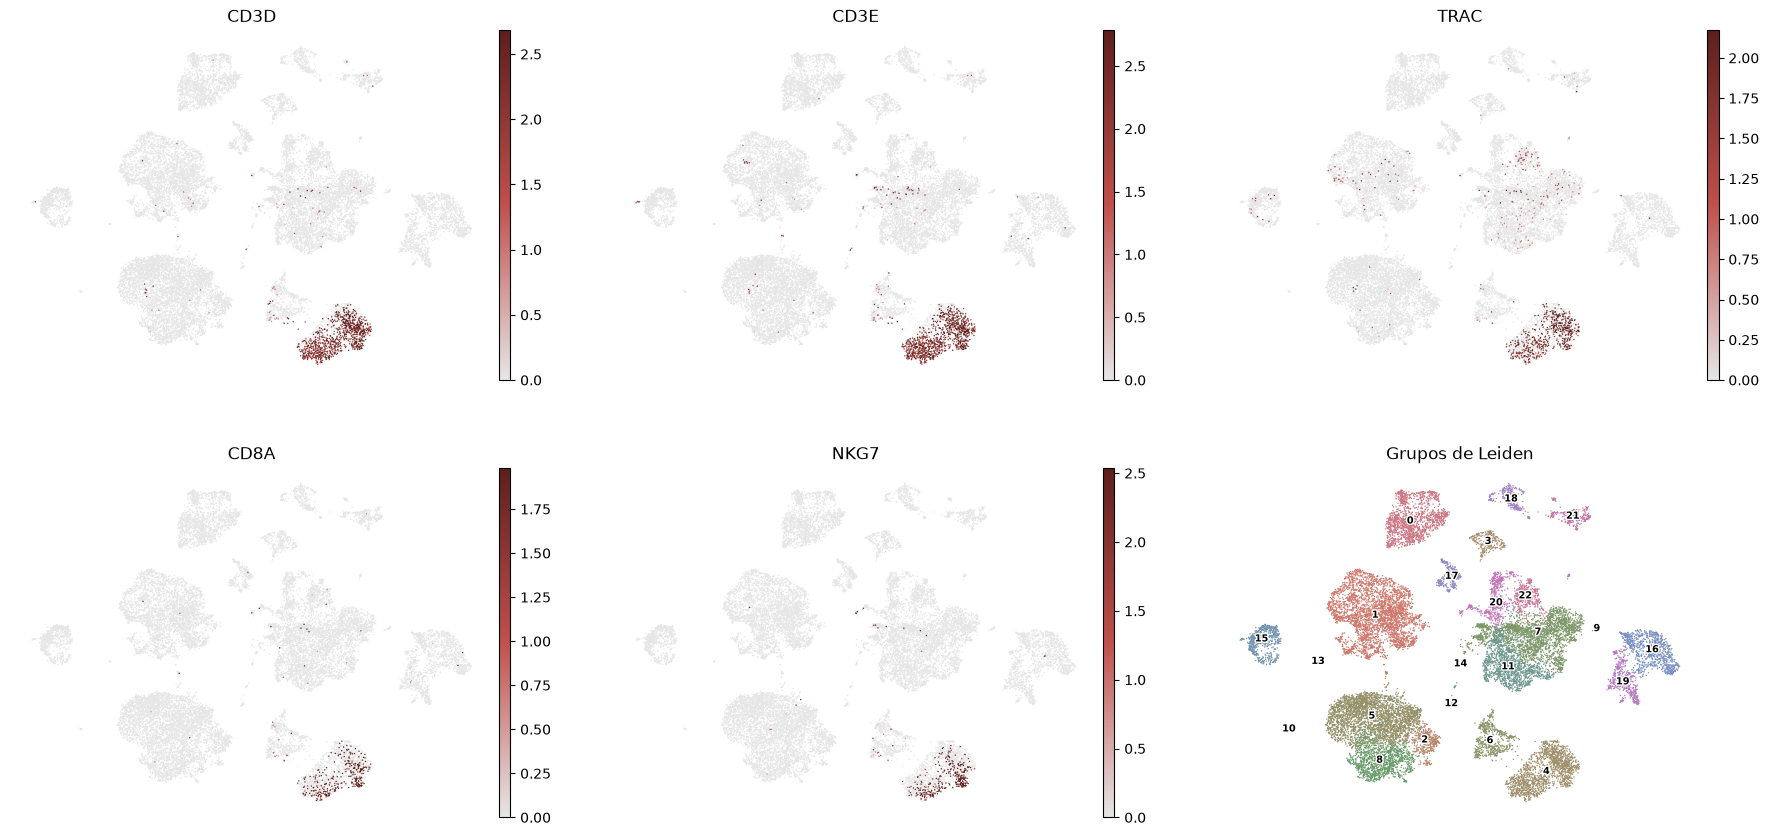

In [10]:
sc.pl.umap(adata, color=["CD3D", "CD3E", "TRAC", "CD8A", "NKG7", "leiden"],
           cmap=CMAP_EXPR, vmax="p99", frameon=False, size=4, ncols=3,
           title=["CD3D", "CD3E", "TRAC", "CD8A", "NKG7", "Grupos de Leiden"],
           legend_loc="on data", legend_fontsize=7, legend_fontoutline=2, show=False)
plt.savefig(DIR_FIGURAS / "umap_marcadores_T.png", dpi=300, bbox_inches="tight")

In [11]:
adata.obs["es_T"] = adata.obs["leiden"] == "4"

t_por_muestra = (adata.obs.groupby(["condicion", "donante", "muestra"], observed=True)["es_T"]
                 .agg(celulas="size", T="sum").reset_index())
t_por_muestra["pct_T"] = (100 * t_por_muestra["T"] / t_por_muestra["celulas"]).round(1)
print(t_por_muestra.to_string(index=False))
print(t_por_muestra.groupby("condicion")["T"].agg(["sum", "min", "median", "max"]))
t_por_muestra.to_csv(DIR_TABLAS / "t_por_muestra.csv", index=False)

condicion donante   muestra  celulas   T  pct_T
       LS     486    486_LS     1134  36    3.2
       LS  BIO023 BIO023_LS     1040  27    2.6
       LS  DER114 DER114_LS     2174 321   14.8
       LS  DER115 DER115_LS     3013 458   15.2
       LS  DER119 DER119_LS     2196  85    3.9
       LS  DER120 DER120_LS      378   6    1.6
       NL     486    486_NL      168   0    0.0
       NL  DER114 DER114_NL     1586 110    6.9
       NL  DER115 DER115_NL     2044 214   10.5
       NL  DER119 DER119_NL      920  58    6.3
       NL  DER120 DER120_NL      767  34    4.4
     Sano     465       465      445  32    7.2
     Sano     632       632      916  37    4.0
     Sano     658       658      489   3    0.6
     Sano  CON161    CON161      845  34    4.0
     Sano  CON171    CON171      904  85    9.4
     Sano  CON194    CON194     1350  41    3.0
           sum  min  median  max
condicion                       
LS         933    6    60.5  458
NL         416    0    58.0  214
Sano

Para los grupos sin marcador clásico se buscan, sin hipótesis previa, los genes que más los distinguen del resto. La prueba de Wilcoxon ordena las células por su expresión de un gen y revisa si las del grupo tienden a quedar arriba. Así se identificaron células de Schwann (CDH19, PMP22, S100B) y glándula sudorípara (DCD, SCGB2A2, AQP5).

In [12]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")

for c in ["3", "16", "19"]:
    df = sc.get.rank_genes_groups_df(adata, group=c).head(15)
    print(f"Cluster {c}:", ", ".join(df["names"]))

Cluster 3: NRXN1, CDH19, SCN7A, GPM6B, PMP22, SPARC, CRYAB, MATN2, CD9, XKR4, PLP1, LGALS1, PRNP, S100B, PCSK2
Cluster 16: KRT19, AQP5, KRT15, SNORC, KRT7, KRT18, SFRP1, SLC12A2, GAPDH, ID4, PDCD4, CLDN4, KRT8, HSPA1B, PPP1R1B
Cluster 19: DCD, SCGB2A2, SCGB1B2P, MUCL1, PIP, SCGB1D2, KRT19, AZGP1, KRT7, KRT18, XBP1, PRR4, SLC12A2, LRRC26, AQP5


Los grupos con mezclas de marcadores de tipos distintos se descartan como dobletes residuales. Como control, los melanocitos deben estar prácticamente ausentes en piel lesional, y los linfocitos T por muestra coinciden con los de la tabla suplementaria S6 de Brunner et al.

In [13]:
anotacion = {
    "0": "Pericito",
    "1": "Fibroblasto",
    "2": "Endotelial",
    "3": "Célula de Schwann",
    "4": "Linfocito T",
    "5": "Endotelial",
    "6": "Mieloide",
    "7": "Queratinocito en diferenciación",
    "8": "Endotelial",
    "9": "Descartar",
    "10": "Descartar",
    "11": "Queratinocito basal",
    "12": "Descartar",
    "13": "Descartar",
    "14": "Descartar",
    "15": "Endotelial linfático",
    "16": "Glándula sudorípara",
    "17": "Melanocito",
    "18": "Músculo liso",
    "19": "Glándula sudorípara",
    "20": "Queratinocito basal",
    "21": "Célula mioepitelial",
    "22": "Queratinocito basal",
}
assert set(anotacion) == set(adata.obs["leiden"].cat.categories)

adata.obs["tipo"] = adata.obs["leiden"].map(anotacion).astype("category")
print(adata.obs["tipo"].value_counts())

adata = adata[adata.obs["tipo"] != "Descartar"].copy()
adata.obs["tipo"] = adata.obs["tipo"].cat.remove_unused_categories()
adata

tipo
Endotelial                         4975
Fibroblasto                        3314
Queratinocito basal                2505
Queratinocito en diferenciación    2504
Linfocito T                        1581
Pericito                           1544
Glándula sudorípara                1429
Endotelial linfático                662
Mieloide                            559
Célula mioepitelial                 330
Músculo liso                        299
Melanocito                          296
Célula de Schwann                   286
Descartar                            85
Name: count, dtype: int64


AnnData object with n_obs × n_vars = 20284 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden', 'es_T', 'tipo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'condicion_colors', 'muestra_colors', 'leiden_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs

tipo                 Linfocito T  Melanocito
condicion muestra                           
LS        486_LS             3.2         0.0
          BIO023_LS          2.6         0.0
          DER114_LS         15.0         0.0
          DER115_LS         15.2         0.1
          DER119_LS          4.0         0.0
          DER120_LS          1.6         0.0
NL        486_NL             0.0         0.0
          DER114_NL          6.9         9.1
          DER115_NL         10.5         1.6
          DER119_NL          6.3         3.6
          DER120_NL          4.4         0.8
Sano      465                7.2         2.7
          632                4.0         0.7
          658                0.6         0.0
          CON161             4.0         5.2
          CON171             9.4         1.0
          CON194             3.0         0.4

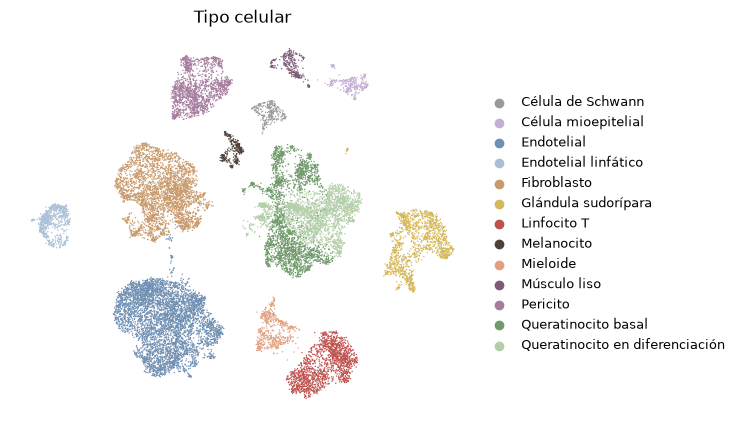

In [14]:
colores_categoria(adata, "tipo", COLORES_TIPO)

fig, ax = plt.subplots(figsize=(6, 5))
sc.pl.umap(adata, color="tipo", ax=ax, frameon=False, size=4, title="Tipo celular",
           legend_fontsize=9, show=False)
fig.savefig(DIR_FIGURAS / "umap_tipos_celulares.png", dpi=300, bbox_inches="tight")

composicion = (pd.crosstab([adata.obs["condicion"], adata.obs["muestra"]],
                           adata.obs["tipo"], normalize="index")
               .mul(100).round(1))
composicion.to_csv(DIR_TABLAS / "composicion_por_muestra.csv")
composicion[["Linfocito T", "Melanocito"]]

In [15]:
adata.write_h5ad(DIR_PROCESADOS / "03_anotado.h5ad")